In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import os
import random
import re
from collections import Counter
from datetime import timedelta

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, KFold, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.utils import to_categorical
from tcn import TCN
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Activation,
    Add,
    BatchNormalization,
    Concatenate,
    Conv1D,
    Dense,
    Dropout,
    Embedding,
    Flatten,
    GlobalAveragePooling1D,
    Input,
    MaxPooling1D,
)
from tensorflow.keras.models import Model, Sequential

# ===== Machine learning / optimization =====
import joblib
import lightgbm as lgb
import optuna
import shap

In [4]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

## Read data and assing age groups

In [ ]:
from joblib import load
X_feat_test, Y_test = load("Data/ML_Test.joblib")
X_DL_test, Y_test = load("Data/DL_Test.joblib")
Y_exact, Y_test_ex = load("Data/DL_Test_Misclass.joblib")

In [12]:
comparison = flatten(Y_test_ex) == flatten(Y_test)

any_false = (comparison == False).any()

In [13]:
np.array_equal(flatten(Y_test_ex), flatten(Y_test))

True

In [5]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# flattens the arrays of single subjects into one array of shape (X,25,2)
X_test_fold = flatten(X_DL_test)
# flattens the arrays of single subjects into one array of shape (X,1)
Y_test_fold = flatten(Y_test)
Y_exact = flatten(Y_exact)

Y_test_rs = to_categorical(Y_test_fold)


# converts train, val, and test data into tensors
X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)


##### Data for static #####


# data are flattened to match the required shape
X_test_feat_all = flatten(X_feat_test)

Y_test_all = Y_test_fold.reshape(-1)

In [6]:
print(X_test_t.shape)
print(Y_test_t.shape)
print(X_test_fold.shape)
print(Y_test_fold.shape)
print(X_test_feat_all.shape)
print(Y_test_all.shape)

(3552429, 25, 1)
(3552429, 4)
(3552429, 25, 1)
(3552429, 1)
(3552429, 83)
(3552429,)


In [7]:
np.bincount(Y_test_all)

array([1199210,  340979,  626318, 1385922])

## Random Forest

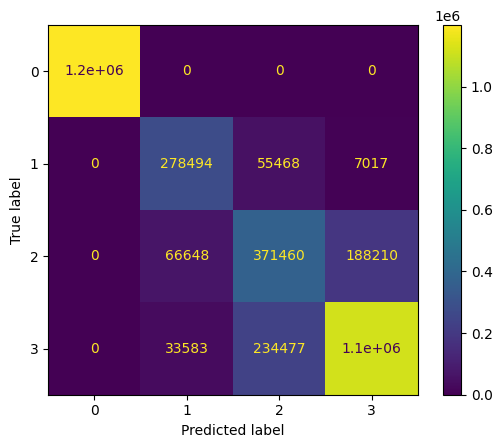


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7353    0.8167    0.7739    340979
           2     0.5616    0.5931    0.5769    626318
           3     0.8513    0.8066    0.8283   1385922

    accuracy                         0.8352   3552429
   macro avg     0.7871    0.8041    0.7948   3552429
weighted avg     0.8393    0.8352    0.8367   3552429



In [ ]:
#shap based feature analysis of RF model 

## now select the best performing fold
model_rf=joblib.load('Saved_Models/model_rf.pkl')

y_pred_prob_rf = model_rf.predict_proba(X_test_feat_all)
y_pred_labels_rf = model_rf.predict(X_test_feat_all)

ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_rf)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_rf, digits=4))

## LightGBM

In [25]:
a = [
 'GlucoseCGM', 'diff_5', 'diff_10', 'diff_20', 'diff_40', 'GlucoseCGM_mean_30min', 'GlucoseCGM_std_30min', 'GlucoseCGM_min_30min', 'GlucoseCGM_max_30min', 'n_30min', 'time_below70_30min', 'time_above200_30min', 'diff_30min', 'slope_30min', 'GlucoseCGM_mean_1hr',
 'GlucoseCGM_std_1hr', 'GlucoseCGM_min_1hr', 'GlucoseCGM_max_1hr', 'n_1hr', 'time_below70_1hr', 'time_above200_1hr', 'diff_1hr', 'slope_1hr', 'GlucoseCGM_mean_2hr', 'GlucoseCGM_std_2hr', 'GlucoseCGM_min_2hr', 'GlucoseCGM_max_2hr', 'n_2hr', 'time_below70_2hr', 'time_above200_2hr', 'diff_2hr', 'slope_2hr', 'GlucoseCGM_mean_4hr', 'GlucoseCGM_std_4hr',  'GlucoseCGM_min_4hr', 'GlucoseCGM_max_4hr', 'n_4hr', 'time_below70_4hr',
 'time_above200_4hr', 'diff_4hr', 'slope_4hr', 'GlucoseCGM_mean_8hr', 'GlucoseCGM_std_8hr', 'GlucoseCGM_min_8hr', 'GlucoseCGM_max_8hr', 'n_8hr', 'time_below70_8hr',
 'time_above200_8hr', 'diff_8hr', 'slope_8hr', 'GlucoseCGM_mean_24hr', 'GlucoseCGM_std_24hr', 'GlucoseCGM_min_24hr', 'GlucoseCGM_max_24hr', 'n_24hr', 'time_below70_24hr',  'time_above200_24hr',  'diff_24hr', 'slope_24hr', 'hypo_points_30m', 'avg_event_duration_min_30m', 'min_since_last_event_30m', 'hypo_points_1h', 'avg_event_duration_min_1h', 'min_since_last_event_1h', 'hypo_points_2h', 'avg_event_duration_min_2h', 'min_since_last_event_2h', 'hypo_points_4h', 'avg_event_duration_min_4h', 'min_since_last_event_4h',  'hypo_points_24h', 'avg_event_duration_min_24h', 'min_since_last_event_24h', 'hour', 'minute', 'dayofweek', 'valid_30min', 'valid_1hr', 'valid_2hr', 'valid_4hr',  'valid_8hr', 'valid_24hr',]

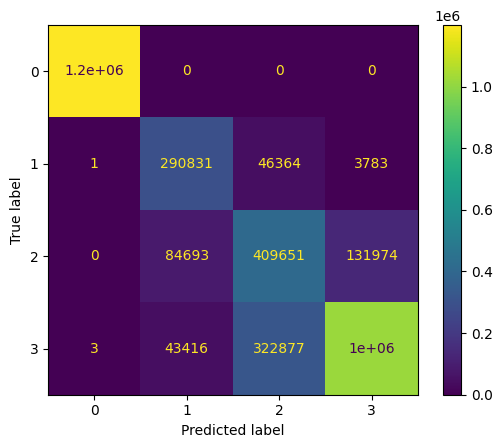


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6942    0.8529    0.7654    340979
           2     0.5259    0.6541    0.5830    626318
           3     0.8825    0.7357    0.8024   1385922

    accuracy                         0.8218   3552429
   macro avg     0.7757    0.8107    0.7877   3552429
weighted avg     0.8412    0.8218    0.8269   3552429



In [ ]:
#shap based feature analysis of LighGBM model 

model_lbgm= joblib.load('Saved_Models/model_lgm.pkl')
X_test_feat_all_df = pd.DataFrame(X_test_feat_all, columns=a)

y_pred_labels_lbgm = model_lbgm.predict(X_test_feat_all_df)
y_pred_prob_lbgm = model_lbgm.predict_proba(X_test_feat_all_df)
ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_lbgm)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_lbgm, digits=4))

## TCN

In [27]:
from joblib import load
X_train, Y_train = load("Data/DataTrain_Multiclass_DL.joblib")

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]


print(len(train_idx))


# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)


print(X_train_fold.shape)

# initiliazes buffer size and batch size 
"""BUFFER_SIZE = len(X_train_fold) 
BATCH_SIZE = 64"""

BATCH_SIZE =  256 #1024 #512 #2048 #256
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)


# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)

1906
(12891361, 25, 1)


111014/111014 ━━━━━━━━━━━━━━━━━━━━ 406s 4ms/step


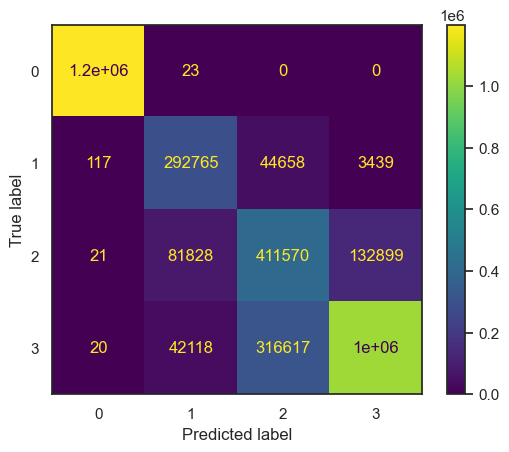

              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999   1199210
           1     0.7025    0.8586    0.7728    340979
           2     0.5325    0.6571    0.5883    626318
           3     0.8828    0.7411    0.8058   1385922

    accuracy                         0.8250   3552429
   macro avg     0.7794    0.8142    0.7917   3552429
weighted avg     0.8433    0.8250    0.8298   3552429



In [ ]:
#IG based feature analysis of FCN model 
from keras.models import load_model

model_tcn = load_model("Saved_Models/TCN_model_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_test_t)

y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
    

final_preds_tcn = y_pred_tcn

y_true_labels_tcn = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn, final_preds_tcn)
plt.show()

report_tcn = classification_report(y_true_labels_tcn, final_preds_tcn, digits=4)
print(report_tcn)

## TCN MHAL

111014/111014 ━━━━━━━━━━━━━━━━━━━━ 584s 5ms/step


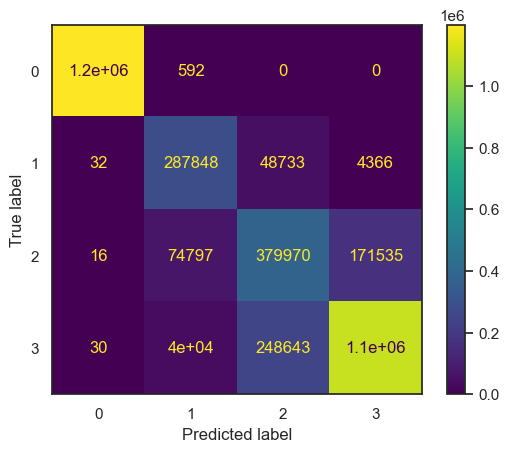

              precision    recall  f1-score   support

           0     0.9999    0.9995    0.9997   1199210
           1     0.7140    0.8442    0.7736    340979
           2     0.5610    0.6067    0.5829    626318
           3     0.8618    0.7918    0.8253   1385922

    accuracy                         0.8343   3552429
   macro avg     0.7842    0.8105    0.7954   3552429
weighted avg     0.8412    0.8343    0.8365   3552429



In [ ]:
#IG based feature analysis of FCN model 
from keras.models import load_model



model_tcn_mhal = load_model("Saved_Models/TCN_model_MHAL_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn_mhal = model_tcn_mhal.predict(X_test_t)

y_pred_tcn_mhal = np.argmax(predictions_tcn_mhal, axis=1) 
    
final_preds_tcn_mhal = y_pred_tcn_mhal


y_true_labels_tcn_mhal = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal, final_preds_tcn_mhal)
plt.show()

report_fcn_tcn_mhal = classification_report(y_true_labels_tcn_mhal, final_preds_tcn_mhal, digits=4)
print(report_fcn_tcn_mhal)

## Ensemble Stacking 

In [ ]:
RF_true = load("Outputs/y_true_RF.joblib")
RF_proba = flatten(load("Outputs/y_pred_prob_RF.joblib"))

LightGBM_true = load("Outputs/y_true_LBG1.joblib")
LightGBM_proba = flatten(load("Outputs/y_pred_prob_LBG1.joblib"))

TCN_true = load("Outputs/y_true_TCN.joblib")
TCN_proba = flatten(load("Outputs/y_pred_prob_TCN.joblib"))

TCN_MHAL_true = load("Outputs/y_true_TCN_MH.joblib")
TCN_MHAL_proba = flatten(load("Outputs/y_pred_prob_TCN_MH.joblib"))

In [31]:
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

from sklearn.linear_model import LogisticRegression
X_meta_val = np.hstack([RF_proba, LightGBM_proba, TCN_proba, TCN_MHAL_proba])  # (n_val, 3*n_classes) 
meta = LogisticRegression(solver="lbfgs", max_iter=500,  C=1.0,class_weight="balanced", random_state =42)
meta.fit(X_meta_val, flatten(RF_true))

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

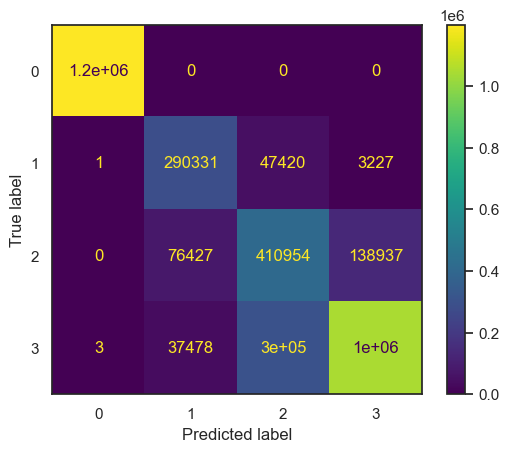

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7182    0.8515    0.7792    340979
           2     0.5403    0.6561    0.5926    626318
           3     0.8804    0.7549    0.8128   1385922

    accuracy                         0.8295   3552429
   macro avg     0.7847    0.8156    0.7962   3552429
weighted avg     0.8452    0.8295    0.8340   3552429



In [32]:
# 500
X_meta_test = np.hstack([y_pred_prob_rf, y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal])  
P_ens_test = meta.predict_proba(X_meta_test)
y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [33]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches



# Inputs you already have:
# y_true    : (N,) int array, values 0–3
# y_pred    : (N,) int array, values 0–3
# minutes   : (N,) float array, minutes before the event (0–120)

def build_pred_time_matrix_polars(y_pred, y_true, minutes):
    """
    y_pred, y_true, minutes: numpy arrays (N,)
    Returns a (4, 25) numpy int matrix:
    rows = predicted class, cols = 5-min bin, values = count
    """
    df = pl.DataFrame({
        "y_pred":  y_pred.astype(np.int8),
        "y_true":  y_true.astype(np.int8),
        "minutes": minutes.astype(np.float32),
    })

    # Bin assignment fully vectorised — no Python loop
    df = df.with_columns(
        pl.col("minutes")
          .floordiv(5)
          .clip(0, 24)
          .cast(pl.Int8)
          .alias("bin")
    )

    # Group-by count: one pass over the data
    counts = (
        df.group_by(["y_pred", "bin"])
          .agg(pl.len().alias("count"))
          .sort(["y_pred", "bin"])
    )

    # Fill into a dense (4, 25) matrix
    matrix = np.zeros((4, 25), dtype=np.int32)
    for row in counts.iter_rows():
        pred_cls, bin_idx, count = row
        if 0 <= pred_cls <= 3 and 0 <= bin_idx <= 24:
            matrix[pred_cls, bin_idx] = count

    return matrix, df   # keep df for temporal confusion below

In [34]:
def build_temporal_confusion_polars(df):
    """
    df: Polars DataFrame with columns y_pred, y_true, bin
    Returns a dict (true_cls, pred_cls) -> (25,) count array
    """
    counts = (
        df.filter(pl.col("y_pred") != pl.col("y_true"))   # misclassified only
          .group_by(["y_true", "y_pred", "bin"])
          .agg(pl.len().alias("count"))
          .sort(["y_true", "y_pred", "bin"])
    )

    result = {}
    for (tc, pc) in [(t, p) for t in range(4) for p in range(4) if t != p]:
        subset = (
            counts
            .filter((pl.col("y_true") == tc) & (pl.col("y_pred") == pc))
        )
        arr = np.zeros(25, dtype=np.int32)
        for row in subset.iter_rows():
            _, _, b, c = row
            if 0 <= b <= 24:
                arr[b] = c
        result[(tc, pc)] = arr

    return result

In [35]:
def build_temporal_error_rates_polars(df):
    """
    Returns dict (tc, pc) -> (25,) float rate array
    """
    # Total per (true_class, bin)
    totals = (
        df.group_by(["y_true", "bin"])
          .agg(pl.len().alias("total"))
    )

    # Misclassified per (true, pred, bin)
    errors = (
        df.filter(pl.col("y_pred") != pl.col("y_true"))
          .group_by(["y_true", "y_pred", "bin"])
          .agg(pl.len().alias("errors"))
    )

    # Join and compute rate — all in Polars, no Python loop
    rates_df = (
        errors
        .join(totals, on=["y_true", "bin"], how="left")
        .with_columns(
            (pl.col("errors") / pl.col("total")).alias("rate")
        )
        .sort(["y_true", "y_pred", "bin"])
    )

    result = {}
    for (tc, pc) in [(t, p) for t in range(4) for p in range(4) if t != p]:
        subset = rates_df.filter(
            (pl.col("y_true") == tc) & (pl.col("y_pred") == pc)
        )
        arr = np.full(25, np.nan, dtype=np.float32)
        for row in subset.iter_rows():
            _, _, b, _, _, rate = row
            if 0 <= b <= 24:
                arr[b] = rate
        result[(tc, pc)] = arr

    return result

In [36]:
# One call — builds matrix and keeps the df for reuse
matrix, df_pl = build_pred_time_matrix_polars(y_pred, flatten(Y_test_fold), flatten(Y_exact))

# Temporal confusion and rates reuse the same df (already in memory)
temporal_conf  = build_temporal_confusion_polars(df_pl)
temporal_rates = build_temporal_error_rates_polars(df_pl)

print("Matrix shape:", matrix.shape)
print("Total predictions:", matrix.sum())
print(f"Memory used by df: {df_pl.estimated_size('mb'):.1f} MB")

Matrix shape: (4, 25)
Total predictions: 3552429
Memory used by df: 23.7 MB


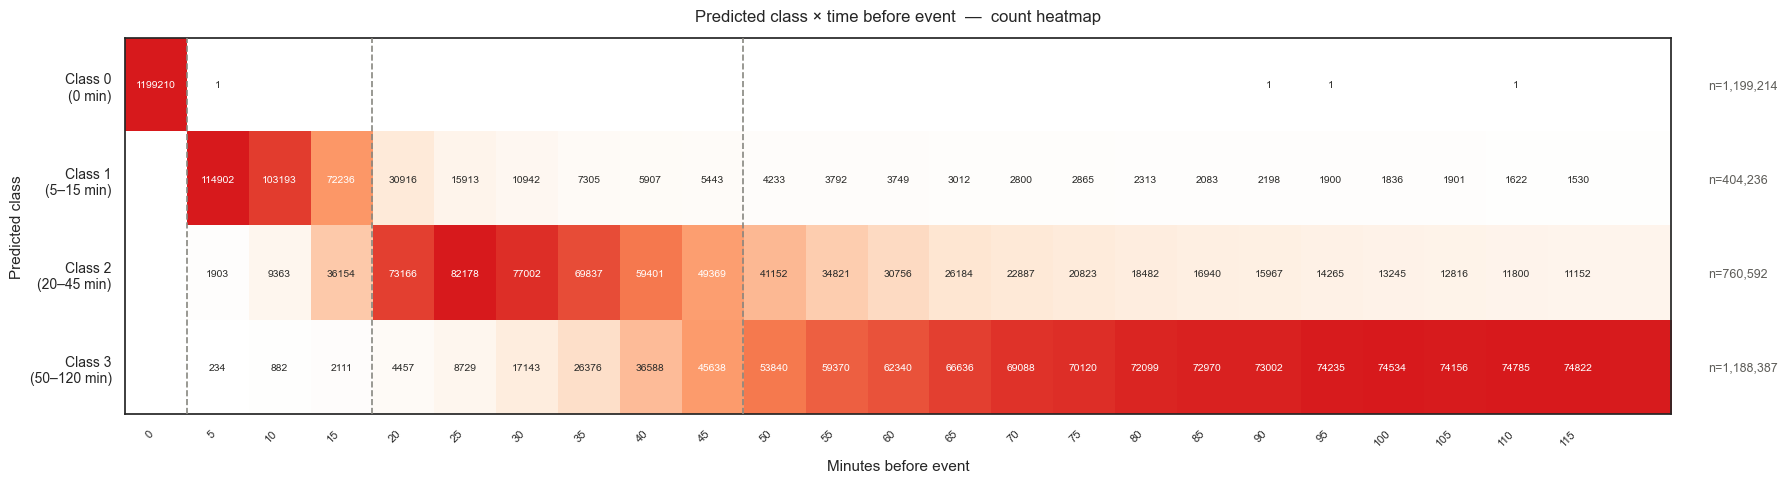

In [47]:
TIME_BINS    = np.arange(0, 125, 5)
BIN_LABELS   = [str(t) for t in TIME_BINS[:-1]]
CLASS_NAMES  = ["Class 0\n(0 min)", "Class 1\n(5–15 min)",
                "Class 2\n(20–45 min)", "Class 3\n(50–120 min)"]
REGION_BOUNDS = [(0, 1), (1, 4), (4, 10), (10, 25)]
REGION_COLORS = ["#E1F5EE", "#EEEDFE", "#FAECE7", "#E6F1FB"]

cmap = LinearSegmentedColormap.from_list(
    "count_map", ["#ffffff", "#FEE5D0", "#FC8D59", "#D7191C"]
)

fig, ax = plt.subplots(figsize=(18, 5))

for (start, end), color in zip(REGION_BOUNDS, REGION_COLORS):
    ax.axvspan(start - 0.5, end, color=color, alpha=0.5, zorder=0)

# per-row normalisation
im_data = np.zeros_like(matrix, dtype=float)
for cls in range(4):
    row_max = matrix[cls].max()
    if row_max > 0:
        im_data[cls] = matrix[cls] / row_max

ax.imshow(im_data, aspect="auto", cmap=cmap,
          vmin=0, vmax=1, interpolation="nearest")

row_totals = matrix.sum(axis=1)
for cls in range(4):
    for b in range(24):
        val = matrix[cls, b]
        if val == 0:
            continue
        text_color = "white" if im_data[cls, b] > 0.6 else "#2C2C2A"
        ax.text(b, cls, str(val), ha="center", va="center",
                fontsize=7.5, color=text_color, fontweight="500")
    ax.text(25.1, cls, f"n={row_totals[cls]:,}",
            ha="left", va="center", fontsize=9, color="#5F5E5A")

for bound_bin in [1, 4, 10]:
    ax.axvline(bound_bin - 0.5, color="#888780",
               linewidth=1.2, linestyle="--", zorder=3)

ax.set_xticks(range(24))
ax.set_xticklabels(BIN_LABELS, fontsize=8, rotation=45, ha="right")
ax.set_yticks(range(4))
ax.set_yticklabels(CLASS_NAMES, fontsize=10)
ax.set_xlabel("Minutes before event", fontsize=11, labelpad=8)
ax.set_ylabel("Predicted class", fontsize=11)

patches = [mpatches.Patch(facecolor=c, alpha=0.5, label=l)
           for c, l in zip(REGION_COLORS,
                           ["Region cls 0", "Region cls 1",
                            "Region cls 2", "Region cls 3"])]
#ax.legend(handles=patches, loc="upper right", fontsize=8,
        #  framealpha=0.9, ncol=2)
ax.set_title("Predicted class × time before event  —  count heatmap",
             fontsize=12, pad=12)

plt.tight_layout()
plt.savefig("temporal_pred_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()